# REES46 Multi-category — EDA октября 2019

## tl;dr

Полный месяц: **42 448 764 события, 3 022 290 пользователей, 166 794 товара, 742 849 событий покупки**. Медиана — **4 события** на пользователя; **42,35%** наблюдаются минимум в два разных дня.

В начале недельных прогнозных окон пользователь и товар по отдельности уже известны для **48,61–67,54%** будущих купленных пар. Это более содержательная оценка доступности истории, чем 99,97% покупок с хотя бы одним действием непосредственно перед ними.

Читаемый `category_code` часто отсутствует, но `category_id` заполнен. Данные подходят для дальнейшей разработки постановки; распределение корзины требует отдельной осторожности. Target, модель и гипотеза автоматизации **не выбраны**.


## Context & Methods

Цель — оценить пригодность данных для первой задачи T-Lab: сильного бустинга и эксперимента по автоматизации признаков. Исследуем весь октябрь, а не ранее просмотренный префикс.

Источники: [REES46](https://data.rees46.com/), [карточка автора](https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store). SHA256 исходного gzip: `8ebca1ad741295297368f2cf0315e3f36853a1a11768fb16babf8c9b83838147`. Подробности восстановления и использования: [docs/data.md](../docs/data.md).

### Key Assumptions

- Строка — действие пользователя; `purchase` не равен заказу. Нет `order_id`, quantity и подтверждённых денежных единиц. Не считаем выручку.
- UTC, точность до секунды. Строго предыдущие события имеют время `< t`; физический порядок внутри секунды не используется.
- Начало и конец месяца обрезают историю и будущие исходы. First-seen означает первое наблюдение **в октябре**, не регистрацию.
- Дубли сохранены в raw-counts и отмечены отдельно. Задержки считаются по уникальным `(user, product, timestamp)` purchase keys, не заказам.
- Отсутствие покупки не означает отрицательный показ. Причинные эффекты и качество рекомендаций здесь не измеряются.
- Основной артефакт — исполняемый notebook; отдельный бизнес-отчёт не создаётся. В Git попадают только код, агрегированные выводы и изображения notebook, без пользовательских событий и ID.


### 1. Data: параметры и полный расчёт

Из корня проекта: `uv sync --locked`, затем `uv run python scripts/eda.py`. Эта ячейка делает то же самое. DuckDB использует ограничение памяти 6–8 GB и временные файлы на диске; исходный gzip не меняется.


In [1]:
from pathlib import Path
import json,sys,os,subprocess,html
from IPython.display import display,Markdown,HTML,Image

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'pyproject.toml').is_file(), 'Запустите notebook из корня проекта или notebooks/'
SOURCE=ROOT/'data/raw/2019-Oct.csv.gz'
OUT=ROOT/'artifacts/eda-october'
DB=ROOT/'data/processed/october.duckdb'
RUN_ANALYSIS=True
OUT.mkdir(parents=True,exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'.matplotlib-cache')
if RUN_ANALYSIS:
    with (OUT/'execution.log').open('w') as log:
        subprocess.run([sys.executable,str(ROOT/'scripts/eda.py'),'--input',str(SOURCE),'--db',str(DB),'--output',str(OUT)],
                       cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
q=json.loads((OUT/'quality.json').read_text())
u=json.loads((OUT/'users.json').read_text())
run=json.loads((OUT/'run.json').read_text())
assert run['quality_complete'] and run['users_complete']
print(f"Полный расчёт завершён: {q['summary']['rows']:,} строк. Агрегаты сохранены локально.")


Полный расчёт завершён: 42,448,764 строк. Агрегаты сохранены локально.


### 2. Независимые проверки итогов

Проверяем суммы и знаменатели из разных агрегатов. Число distinct users по группам known/new item не суммируем: пользователь может присутствовать в двух группах.


In [2]:
s=q['summary']; us=u['user_summary']; w=u['warm_purchase_rows']; d=u['view_to_purchase_delay']
assert sum(r['events'] for r in q['events'])==sum(r['events'] for r in q['daily'])==s['rows']==us['events_with_user']
assert sum(r['users'] for r in u['user_event_bins'])==us['users']==sum(r['first_seen_users'] for r in u['daily_users'])
assert sum(r['purchase_rows'] for r in u['pre_purchase_user_history'])==w['purchase_rows']
assert next(r['purchase_rows'] for r in u['pre_purchase_user_history'] if r['prior_event_bin']=='01: 0')==w['purchase_rows']-w['warm_user_rows']
assert d['matched_purchase_keys']+d['unmatched_purchase_keys']==d['purchase_keys']
assert d['purchase_keys']+q['duplicates']['purchase_duplicate_surplus']==d['raw_purchase_rows']
assert 0<d['delay_seconds_quantiles_matched_keys'][0]<=d['delay_seconds_quantiles_matched_keys'][-1]
assert d['matched_within_one_hour']<=d['matched_within_one_day']<=d['matched_within_seven_days']<=d['matched_purchase_keys']
for row in u['daily_users']: assert row['first_seen_users']+row['returning_observed_users']==row['active_users']
for row in u['cutoff_purchase_coverage']:
    assert row['distinct_purchased_pairs']<=row['distinct_purchase_keys']<=row['raw_purchase_rows']
print('Проверки сумм, raw/key-знаменателей, временных групп и вложенных интервалов пройдены.')


Проверки сумм, raw/key-знаменателей, временных групп и вложенных интервалов пройдены.


## Results

### Объём, типы действий и динамика


event_type,events,users,products
view,"40,779,399","3,022,130","166,794"
cart,"926,516","337,117","11,765"
purchase,"742,849","347,118","42,241"


Matplotlib is building the font cache; this may take a moment.


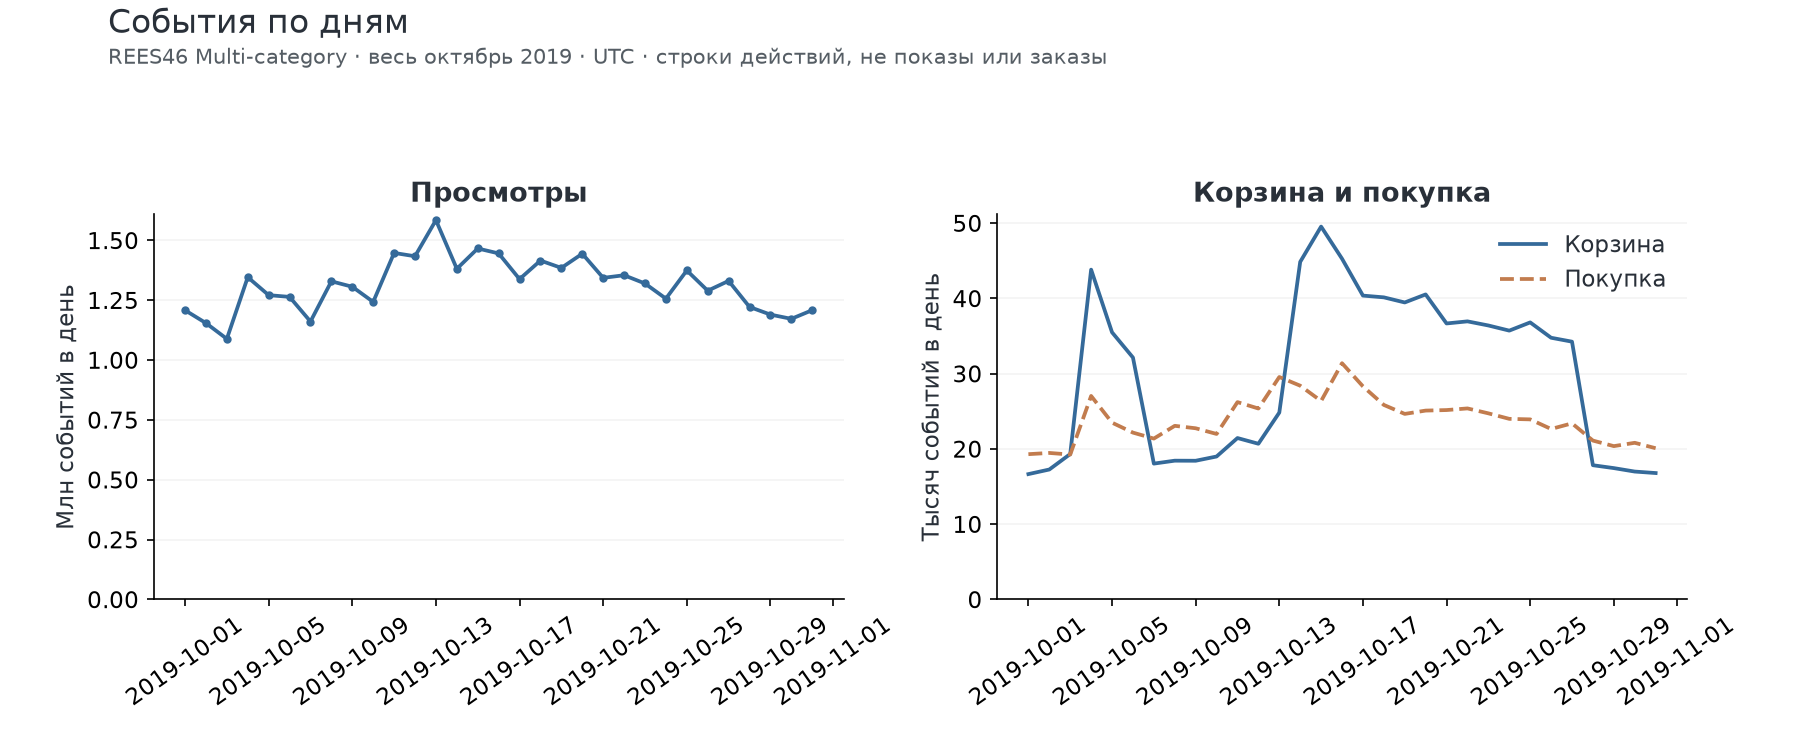

In [3]:
def table(rows):
    cols=list(rows[0]) if rows else []
    def fmt(x):
        if isinstance(x,float): return f'{x:,.3f}'
        if isinstance(x,int): return f'{x:,}'
        return str(x)
    body='<table><thead><tr>'+''.join('<th>'+html.escape(c)+'</th>' for c in cols)+'</tr></thead><tbody>'
    for row in rows: body+='<tr>'+''.join('<td>'+html.escape(fmt(row[c]))+'</td>' for c in cols)+'</tr>'
    display(HTML(body+'</tbody></table>'))

table(q['events'])
sys.path.insert(0,str(ROOT/'scripts'))
from plots import create
figures=create(q,u,OUT/'figures')
display(Image(filename=str(figures[0])))


**Интерпретация.** В октябре фактически три типа действий: view, cart, purchase; remove_from_cart в этом файле не наблюдается. Корзина не является обязательной наблюдаемой ступенью покупки. Доля cart/view заметно меняется около 14 и 28 октября; причина неизвестна — возможны особенности продукта, логирования или поведения. Не исправляем этот сдвиг автоматически и не принимаем cart за универсальную метку намерения.


### Качество и свойства товаров


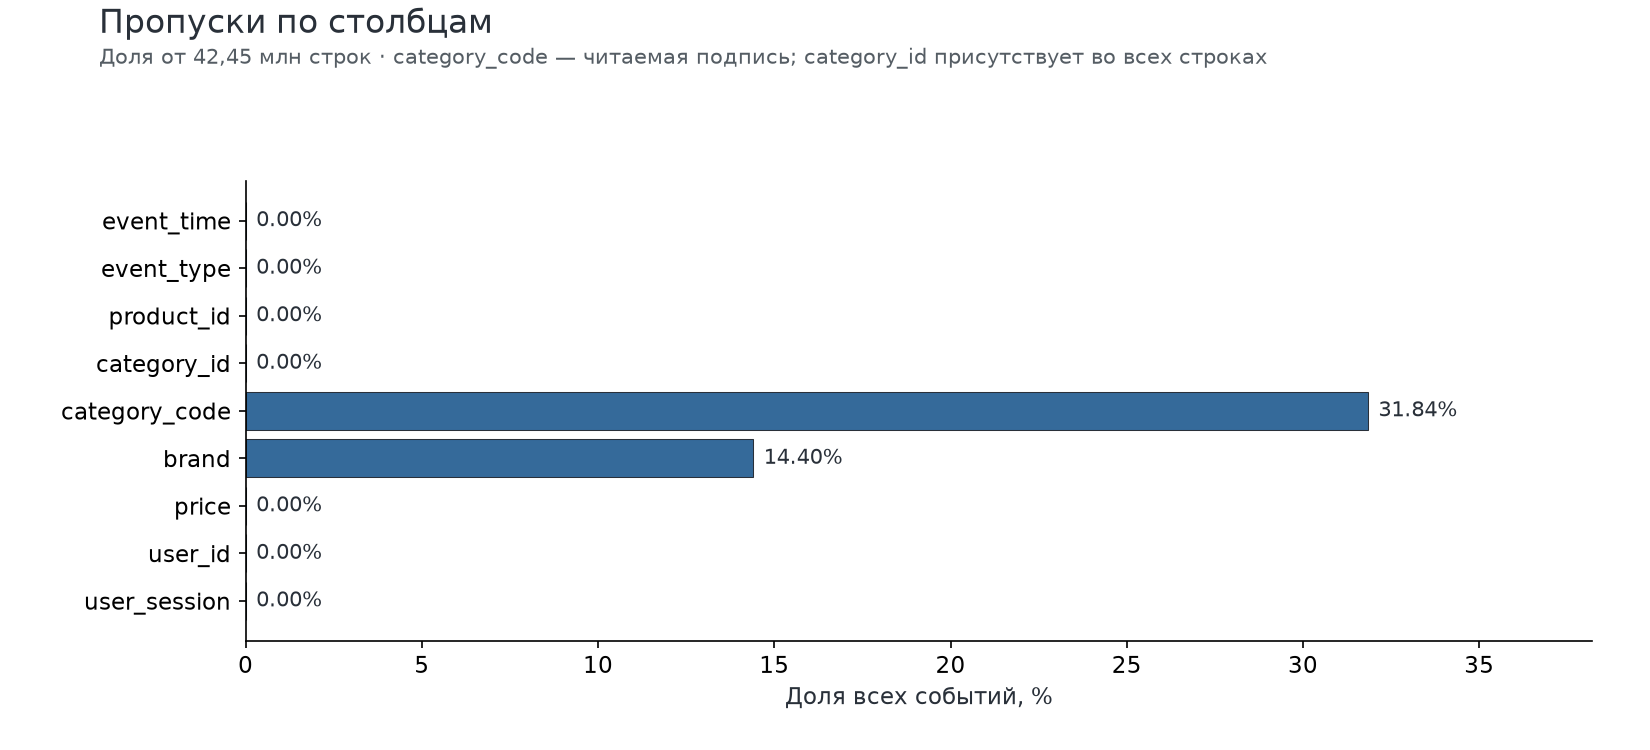

показатель,значение
Лишние точные дубли после типизации,"30,220"
Лишние purchase-дубли,76
События с нулевой ценой,"68,673"
Товары с изменяющейся ценой,"57,550"
Товары с несколькими non-null brand,137


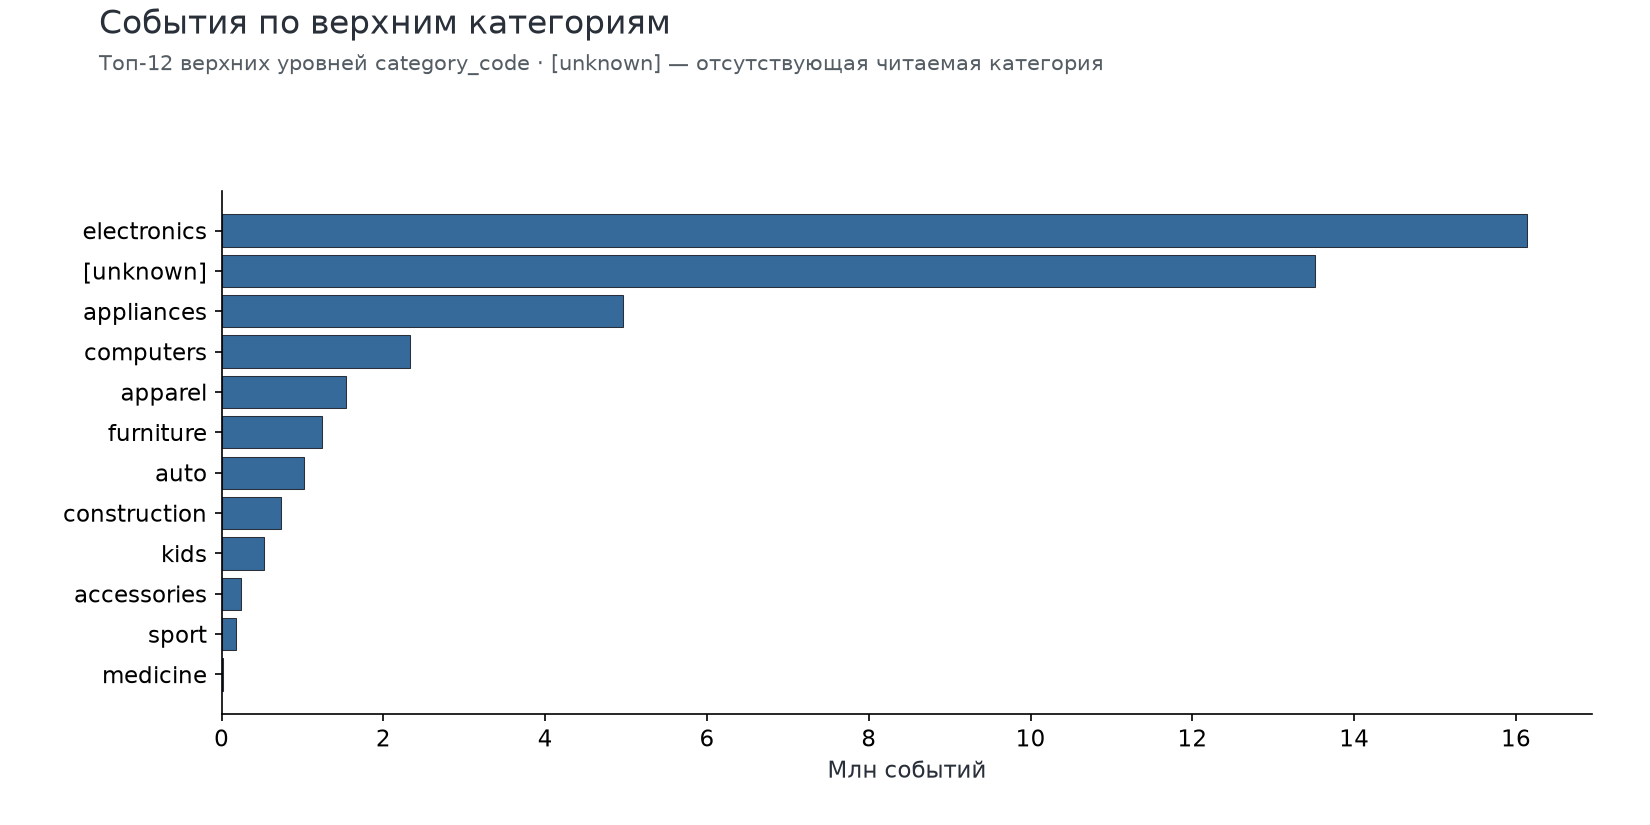

In [4]:
display(Image(filename=str(figures[1])))
table([{'показатель':'Лишние точные дубли после типизации','значение':q['duplicates']['duplicate_surplus']},
       {'показатель':'Лишние purchase-дубли','значение':q['duplicates']['purchase_duplicate_surplus']},
       {'показатель':'События с нулевой ценой','значение':s['zero_prices']},
       {'показатель':'Товары с изменяющейся ценой','значение':q['metadata_variation']['changing_prices']},
       {'показатель':'Товары с несколькими non-null brand','значение':q['metadata_variation']['multiple_brands']}])
display(Image(filename=str(figures[3])))


Читаемый category_code отсутствует примерно в **31,84%** строк, brand — **14,40%**. Category ID заполнен во всех строках; отсутствие подписи не делает категорию неизвестной для модели. У 57 550 товаров меняется наблюдаемая цена, у 137 — бренд. Это не автоматически ошибки. Будущие признаки не должны брать последнюю цену или заполнять прошлое более поздними metadata.

Строгий CSV-парсер прошёл весь файл; это fail-fast проверка типов, а не отдельный подсчёт успешно исправленных malformed values. Дубли и нулевые цены сохранены. У двух строк отсутствует session ID. Категории на графике — top12, а не исчерпывающее разбиение.


### Пользователи и история перед покупкой


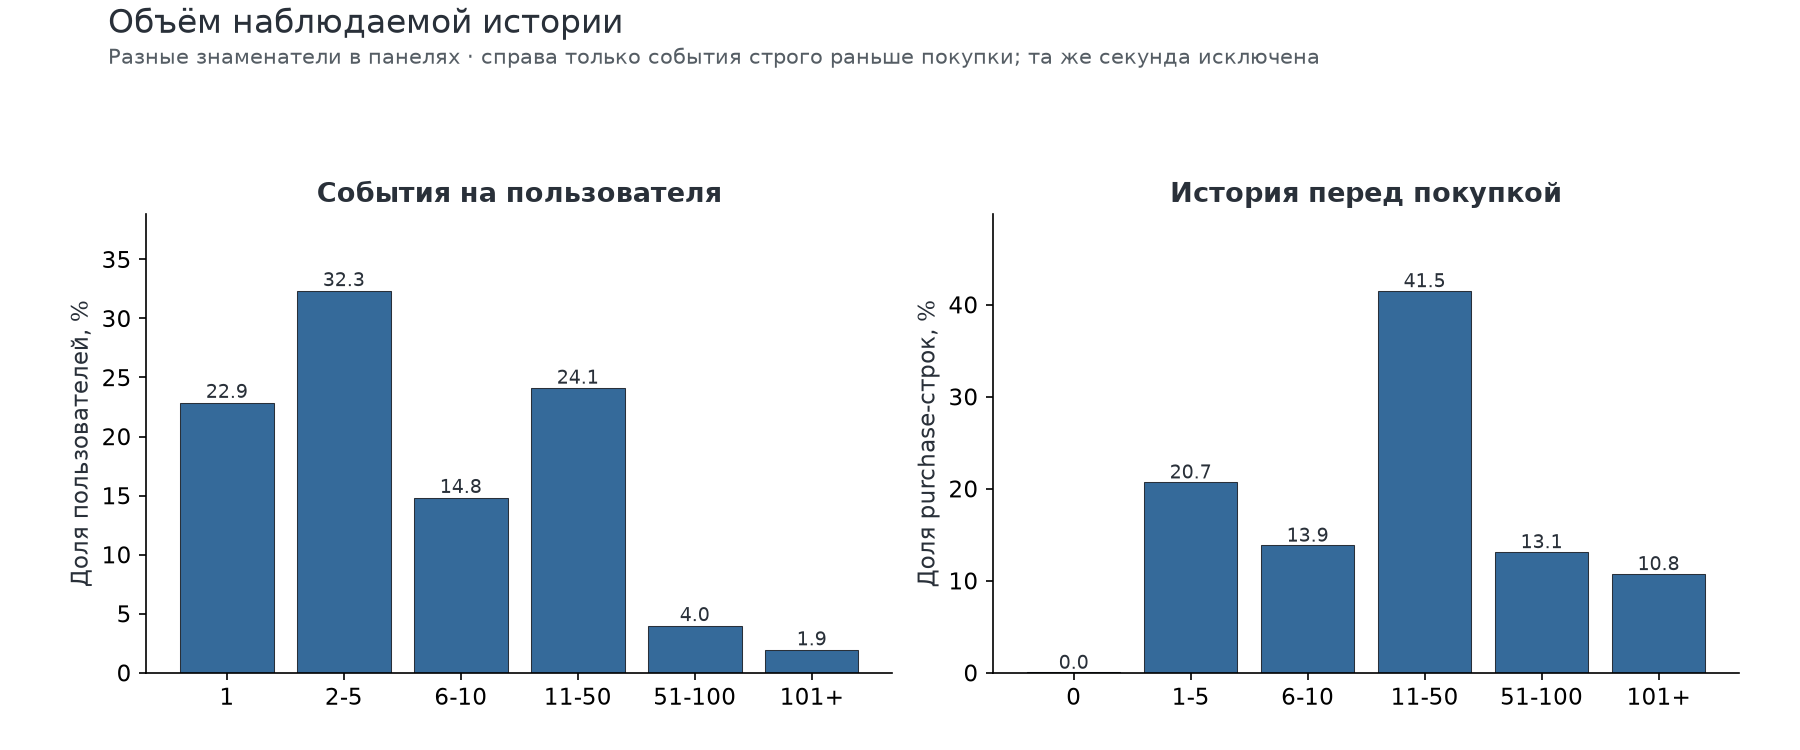

показатель,значение
"Пользователи, всего","3,022,290"
С единственным событием,"691,246"
Активны минимум в 2 дня,"1,279,795"
Активны минимум в 7 дней,"138,478"


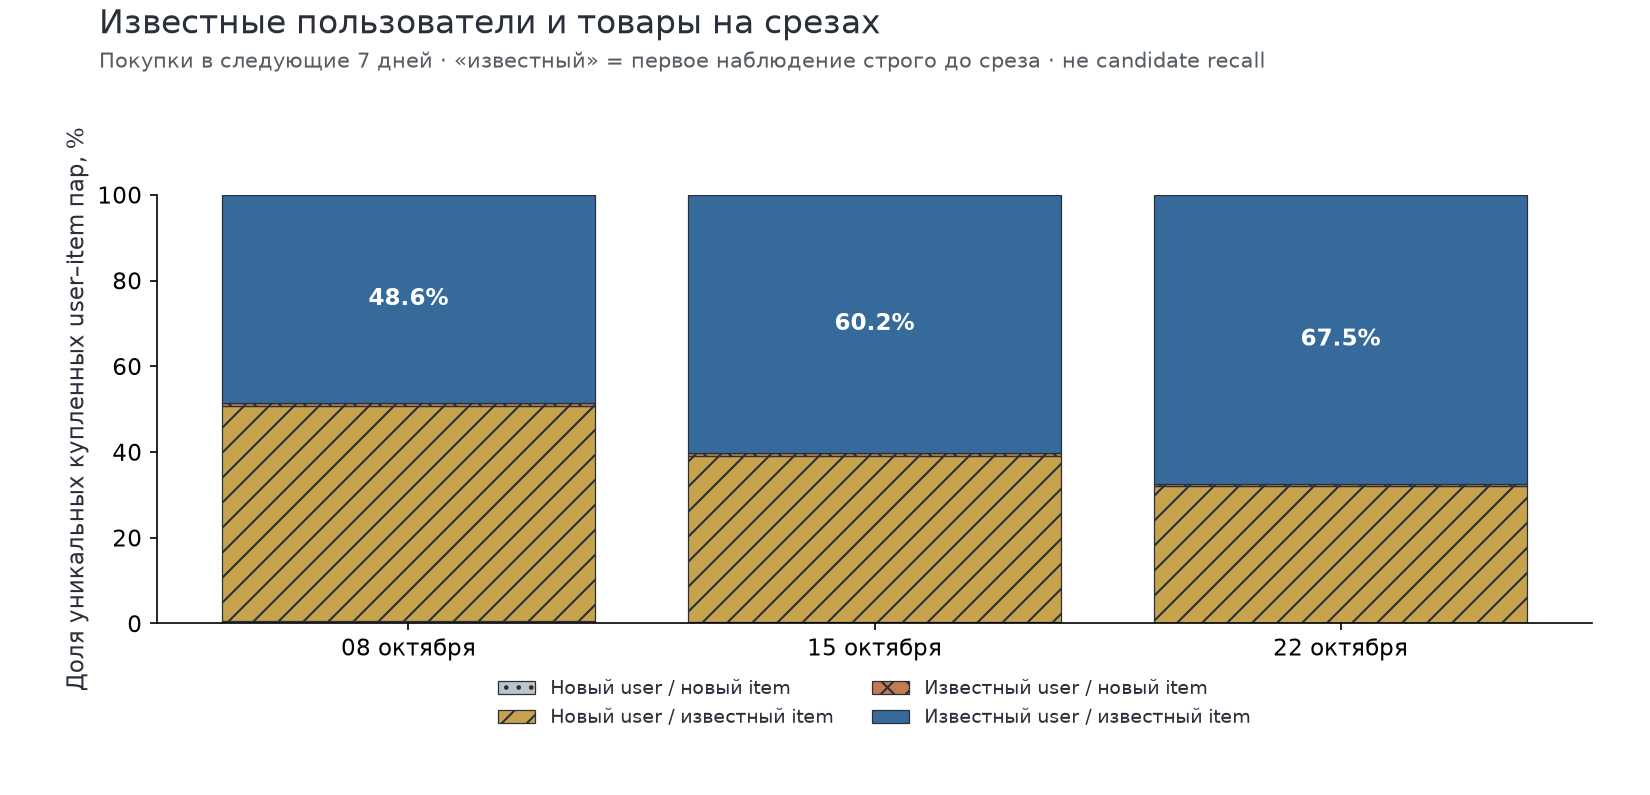

In [5]:
display(Image(filename=str(figures[2])))
table([{'показатель':'Пользователи, всего','значение':us['users']},
       {'показатель':'С единственным событием','значение':us['users_one_event']},
       {'показатель':'Активны минимум в 2 дня','значение':us['users_two_or_more_active_days']},
       {'показатель':'Активны минимум в 7 дней','значение':us['users_seven_or_more_active_days']}])
display(Image(filename=str(figures[4])))


Медиана по всем пользователям — 4 события и один активный день; 42,35% активны минимум в два дня, только 4,58% — минимум в семь. При этом у 65,40% purchase-строк больше 10 строго предшествующих событий пользователя. Это разные популяции и знаменатели.

Наличие истории непосредственно перед покупкой (99,97%) не доказывает, что пользователь известен на момент рекомендаций в начале дня/недели. Для недель после 8/15/22 октября доля будущих купленных пар с отдельно известными user и item — 48,61/60,24/67,54%. Это не доля повторно покупаемых пар и не recall генератора кандидатов.


### Сессии, порядок действий и задержки


показатель,значение
"Пары (user, session)","9,244,770"
Session ID у нескольких users,348
Сессии с покупкой,"629,560"
Сессии с покупкой без cart,"337,699"
Строки в tied user-time группах,"76,054"


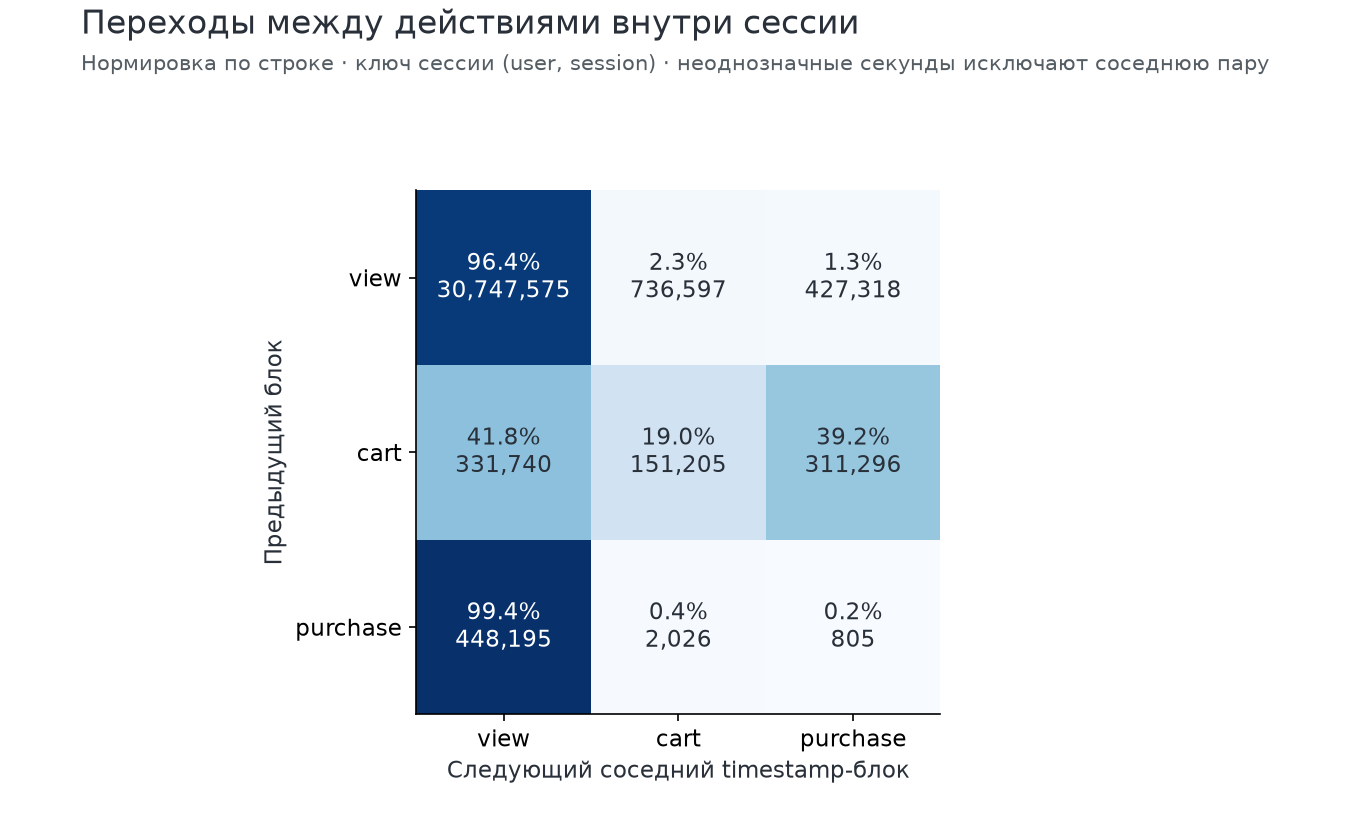

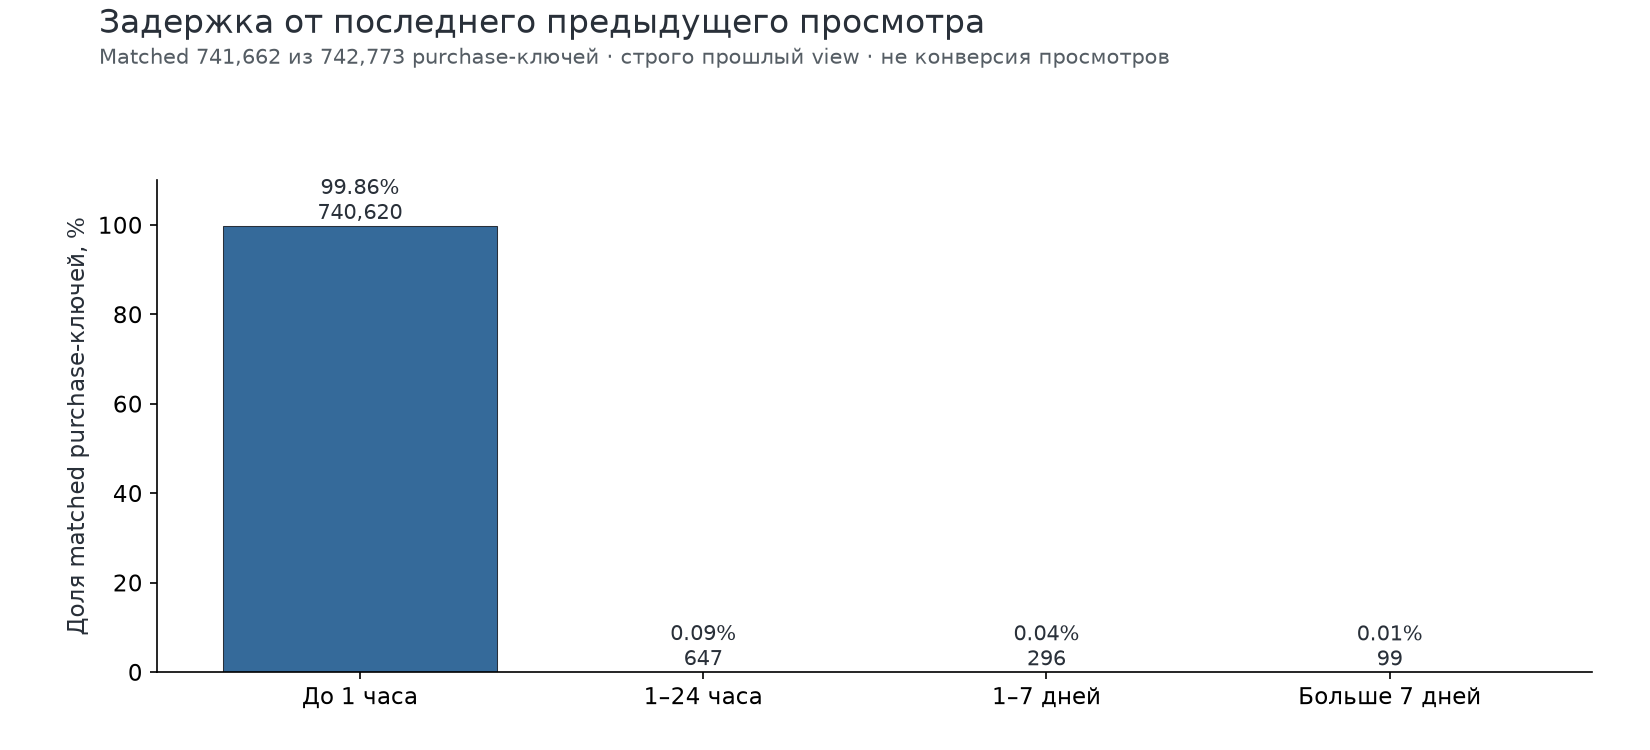

In [6]:
table([{'показатель':'Пары (user, session)','значение':q['sessions']['user_sessions']},
       {'показатель':'Session ID у нескольких users','значение':q['session_identity']['ids_with_multiple_users']},
       {'показатель':'Сессии с покупкой','значение':q['sessions']['sessions_with_purchase']},
       {'показатель':'Сессии с покупкой без cart','значение':q['sessions']['purchase_sessions_without_cart']},
       {'показатель':'Строки в tied user-time группах','значение':q['timestamp_ties']['rows_in_tied_groups']}])
display(Image(filename=str(figures[6])))
display(Image(filename=str(figures[5])))


Session ID не глобально уникален по пользователю: 348 ID встречаются у нескольких users. Для сессий используем составной ключ (user_id, user_session). Переходы определены между соседними секундными блоками, внутри которых наблюдается только один тип действия. Неоднозначная секунда исключает пары с обоих соседних направлений; одинаковые секунды не упорядочиваем по строкам.

Для 99,85% уникальных purchase-ключей найден строго предшествующий view того же user–item. Медиана времени от **последнего** такого просмотра — 89 секунд. Взгляд выбран условно на уже случившуюся покупку; это не распределение будущей конверсии всех просмотров и не основание выбирать горизонт labels. Один старый view может быть ближайшим для нескольких покупок. Ненайденный view может лежать за границей октября.


## Takeaways

1. Датасет пригоден для дальнейшего проектирования эксперимента; не требуется брать все семь месяцев для первого baseline.
2. Нужно оценивать отдельно пользователей с накопленной историей и впервые наблюдаемых на будущем срезе. Выбирать cohort по будущим покупкам нельзя.
3. Категории, бренд, цена и недавняя активность дают понятные кандидаты для ручного baseline; полезность автоматического поиска ещё не проверена.
4. Сначала выбрать единицу прогноза: конверсия после view либо ранжирование будущих взаимодействий. Затем определить label maturity, candidate protocol и временные splits.
5. Сдвиги cart-событий, дубли, изменяемые цены, секундные ties и границы месяца должны войти в протокол. Ни один из них здесь не исправлен скрытно.

**Статус:** EDA полного месяца; модель не обучалась, target и гипотеза не выбраны. Числа сверены независимыми reviewers и программными инвариантами. Источник, данные и промежуточные таблицы остаются локально; notebook содержит только агрегаты.
